# 01. 패널 만들기 — AI 노출도 × 직업별 청년 취업자

KOSIS 직업 중분류 취업자, ILO 노출도, ECI를 하나의 분석용 패널로 만든다. 03~06 노트북은 모두 이 노트북의 출력에서 시작한다.

- **1부**: 원자료를 읽어 직업 중분류 × 반기 패널(`panel_mid.csv`)을 만들고 구조를 점검한다(EDA E1~E9).
- **2부**: 분석용 변수와 표본 표시를 붙여 `panel_analysis.csv`와 변수 설명표를 만든다.


## 1부. EDA — AI 노출도와 청년 고용 (E1~E9)

설계 문서 `docs/ai_exposure_design_eda.md` 4절을 실행한다. 원본은 `data/raw/`(2026-11-11 수집)에 있고, 경로는 `src/config.py`를 따른다. 그림은 `reports/figures/`에 저장한다.

- 결과 변수: KOSIS `DT_1ES3B28J` 직업 중분류 × 연령 취업자 (반기, 2013 상~2026 상)
- 처치 강도: ILO WP140 직업별 생성형 AI 노출도 → KSCO 8차 중분류
- 시간 변수: Epoch Capabilities Index (ECI)

E2(월별 공표치 재계산)는 월별 표를 받지 않아 이번 실행에서 제외했다.

In [41]:
import sys

sys.path.append("..")  # 노트북 폴더 기준으로 src를 찾는다 (README 6절)
from src import config

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import font_manager
from matplotlib.patches import Patch

try:
    display
except NameError:  # 스크립트로 실행할 때
    def display(x):
        print(x.to_string() if hasattr(x, "to_string") else x)

RAW, OUT, FIG = config.DATA_RAW, config.DATA_PROCESSED, config.FIGURES
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(exist_ok=True)

# 색: 글자는 잉크 색, 노출도 3분위는 한 색상의 밝기 단계(순서형)
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE = "#2a78d6"
ORDER = ["하", "중", "상"]
TERC = {"하": "#86b6ef", "중": "#2a78d6", "상": "#0d366b"}

_fonts = {f.name for f in font_manager.fontManager.ttflist}
FONT = next(f for f in ["AppleGothic", "Malgun Gothic", "NanumGothic", "DejaVu Sans"] if f in _fonts)
sns.set_theme(style="whitegrid", font=FONT, rc={
    "axes.unicode_minus": False, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.labelsize": 9,
    "axes.titleweight": "bold", "axes.titlesize": 10, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
CHATGPT = 2022 + 11 / 12  # 2022-11-30 출시


def mark_chatgpt(ax, label=True):
    ax.axvline(CHATGPT, color=MUTED, lw=1, ls="--", zorder=1)
    if label:
        ax.annotate("ChatGPT 출시", (CHATGPT, 1), xycoords=("data", "axes fraction"), xytext=(-4, -3),
                    textcoords="offset points", ha="right", va="top", fontsize=7.5, color=INK2)


def end_label(ax, x, y, text):
    ax.annotate(text, (x, y), xytext=(5, 0), textcoords="offset points", va="center", fontsize=8, color=INK2)

asdfasdf




### E1. 패널 구성과 구조 점검

KOSIS CSV는 머리글이 2행(시점, 항목)이고, 값이 전부 빈 항목 열은 시점마다 빠져 있다. 열 위치가 아니라 머리글로 읽는다.

In [42]:
raw = pd.read_csv(RAW / "kosis" / "DT_1ES3B28J_직업중분류x연령_2013H1-2026H1.csv", encoding="cp949", header=None, dtype=str)
prd = raw.iloc[0, 1:].str.split().str[0].str[1:]   # 'H201301 2013.1/2' → '201301'
itm = raw.iloc[1, 1:].str.split().str[0]            # 'T20 연령(15~29세)' → 'T20'
long = raw.iloc[2:].melt(id_vars=[0], var_name="col", value_name="v").rename(columns={0: "label"})
long["code"] = long.label.str.split().str[0]
long["name"] = long.label.str.split(n=1).str[1].str.replace("?", "·", regex=False)  # CP949에서 깨진 가운뎃점
long["period"], long["item"] = long.col.map(prd), long.col.map(itm)

ITEMS = {"T00": "total", "T20": "y15_29", "T21": "a30_39", "T22": "a40_49", "T23": "a50_59", "T24": "a60p"}
cnt = long[long.item.isin(ITEMS)].assign(n=lambda d: pd.to_numeric(d.v, errors="coerce").fillna(0))  # '-'(해당 없음) → 0
panel = cnt.pivot(index=["code", "name", "period"], columns="item", values="n").rename(columns=ITEMS).reset_index()
panel.columns.name = None
flag = long.loc[long.item == "T201", ["code", "period", "v"]].assign(y_flag=lambda d: d.v.eq("*")).drop(columns="v")
panel = panel.merge(flag, on=["code", "period"], how="left")
panel["y_flag"] = panel.y_flag.fillna(False).astype(bool)   # 청년 추정치 RSE 25% 이상
panel["a30_59"] = panel[["a30_39", "a40_49", "a50_59"]].sum(axis=1)
panel["year"], panel["half"] = panel.period.str[:4].astype(int), panel.period.str[4:].astype(int)
panel["time"] = panel.year + np.where(panel.half == 1, 3.5, 9.5) / 12   # 조사 기준월: 4월·10월
panel["post"] = panel.period >= "202301"

total = panel[panel.code == "0"].set_index("period")
major = panel[(panel.code.str.len() == 1) & (panel.code != "0")]
mid = panel[panel.code.str.len() == 2].copy()
mid["major"] = mid.code.str[0]

d_mid = (mid.groupby(["major", "period"]).total.sum() - major.set_index(["code", "period"]).total).abs().max()
d_maj = (major.groupby("period").total.sum() - total.total).abs().max()
d_age = (panel[["y15_29", "a30_39", "a40_49", "a50_59", "a60p"]].sum(axis=1) - panel.total).abs().max()
print(f"중분류 {mid.code.nunique()}개 × 시점 {mid.period.nunique()}개 = {len(mid):,}셀")
print(f"합계 차이(천명): 중분류→대분류 {d_mid:.0f}, 대분류→계 {d_maj:.0f}, 연령 합→취업자 {d_age:.0f}")
assert max(d_mid, d_maj, d_age) <= 3, "합계가 반올림 범위를 벗어남"

중분류 56개 × 시점 27개 = 1,512셀
합계 차이(천명): 중분류→대분류 3, 대분류→계 1, 연령 합→취업자 2


### E3. 결과 변수 추이

,2013,2019,2022,최근 12개월,2022 대비(%p)
20~29세,56.83,58.16,60.39,59.16,-1.23
30~59세,75.07,76.62,77.51,79.86,2.35
60세 이상,38.43,41.47,44.47,46.49,2.02


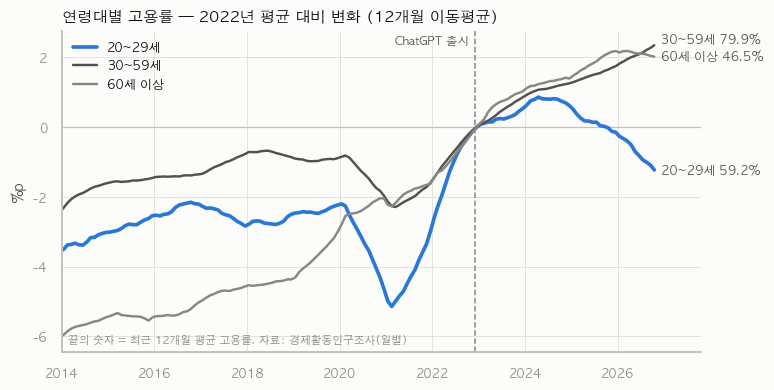

In [43]:
# 고용률 = 취업자 ÷ 인구. 직업별 표에는 인구가 없어서 전국 월별 표(경제활동인구조사)로 계산한다.
# 취업자 수는 인구 증감(청년 감소, 60세 이상 증가)이 섞이므로, 연령대끼리 비교할 때는 고용률을 쓴다.
# 청년은 20~29세로 본다(15~19세는 대부분 학생이라 고용률 8% 안팎, 이들의 비중 변화가 15~29세 고용률을 흔든다).
# 월별 값은 계절에 따라 출렁여서 12개월 이동평균으로 그린다.
mraw = pd.read_csv(next((RAW / "kosis").glob("DT_1DA7002S_*.csv")), encoding="cp949", header=None, dtype=str)
mper, mitem = mraw.iloc[0, 1:].str[1:7], mraw.iloc[1, 1:].str[:3]


def mseries(age, it):
    r = mraw[mraw[0].str.startswith(age)].iloc[0, 1:]
    s = pd.to_numeric(r[(mitem == it).values], errors="coerce")
    s.index = pd.to_datetime(mper[(mitem == it).values].values, format="%Y%m")
    return s


AGES = {"20~29세": ["20 "], "30~59세": ["30 ", "40 ", "50 "], "60세 이상": ["60 "]}
er = pd.DataFrame({k: 100 * sum(mseries(a, "T30") for a in v) / sum(mseries(a, "T10") for a in v) for k, v in AGES.items()})
er_ma = er.rolling(12).mean().dropna()
chg = er_ma - er[er.index.year == 2022].mean()          # 2022년 평균 대비 변화(%p)
xt = er_ma.index.year + (er_ma.index.month - 0.5) / 12

fig, ax = plt.subplots(figsize=(7.5, 3.8))
last = chg.iloc[-1].sort_values()
ypos = last.copy()
for i in range(1, len(ypos)):                       # 끝 이름표가 겹치지 않게 최소 0.5%p 띄운다
    ypos.iloc[i] = max(ypos.iloc[i], ypos.iloc[i - 1] + 0.5)
for col, color, lw in [("20~29세", BLUE, 2.4), ("30~59세", INK2, 1.6), ("60세 이상", MUTED, 1.6)]:
    ax.plot(xt, chg[col], color=color, lw=lw, label=col)
    ax.annotate(f"{col} {er_ma[col].iloc[-1]:.1f}%", (xt[-1], chg[col].iloc[-1]), xytext=(xt[-1] + 0.15, ypos[col]),
                va="center", fontsize=8, color=INK2)
ax.axhline(0, color=AXIS, lw=0.8, zorder=1)
mark_chatgpt(ax)
ax.set(title="연령대별 고용률 — 2022년 평균 대비 변화 (12개월 이동평균)", xlabel="", ylabel="%p", xlim=(2014, 2027.8))
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.text(0.01, 0.03, "끝의 숫자 = 최근 12개월 평균 고용률. 자료: 경제활동인구조사(월별)", transform=ax.transAxes, fontsize=7, color=MUTED)
fig.savefig(FIG / "fig1_연령대별_고용률.png")

tbl = pd.DataFrame({"2013": er[er.index.year == 2013].mean(), "2019": er[er.index.year == 2019].mean(),
                    "2022": er[er.index.year == 2022].mean(), "최근 12개월": er.iloc[-12:].mean()})
tbl["2022 대비(%p)"] = tbl["최근 12개월"] - tbl["2022"]
display(tbl.round(2))


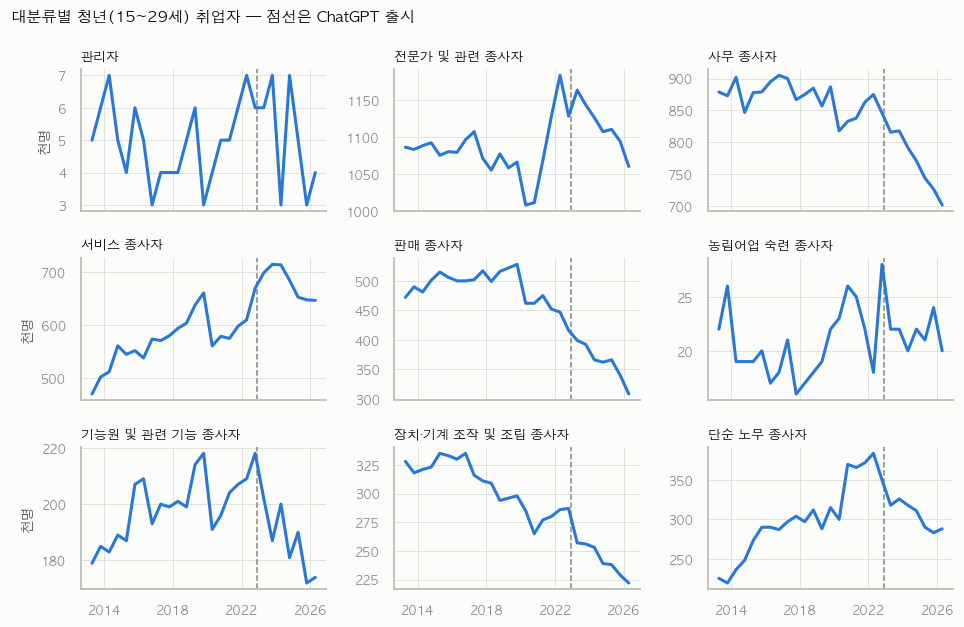

In [44]:
g1 = sns.relplot(data=major.sort_values(["code", "time"]), x="time", y="y15_29", col="name", col_wrap=3, kind="line",
                 color=BLUE, height=1.9, aspect=1.55, facet_kws={"sharey": False})
g1.set_titles("{col_name}", size=8.5)
g1.set_axis_labels("", "천명")
g1.set(xticks=[2014, 2018, 2022, 2026])
for ax in g1.axes.flat:
    mark_chatgpt(ax, label=False)
g1.figure.suptitle("대분류별 청년(15~29세) 취업자 — 점선은 ChatGPT 출시", x=0.01, y=1.03, ha="left", fontsize=10, fontweight="bold")
g1.savefig(FIG / "fig2_대분류별_청년취업자.png")

### E4. 청년 셀 신뢰도

KOSIS는 상대표준오차(RSE)가 25% 이상인 추정치에 `*`를 붙인다.

표시된 셀 223/1512 (14.7%), 그 셀의 청년 취업자 비중 0.40%
시점의 절반 이상에서 표시된 중분류: ['12', '13', '14', '15', '27', '62', '63', '88']


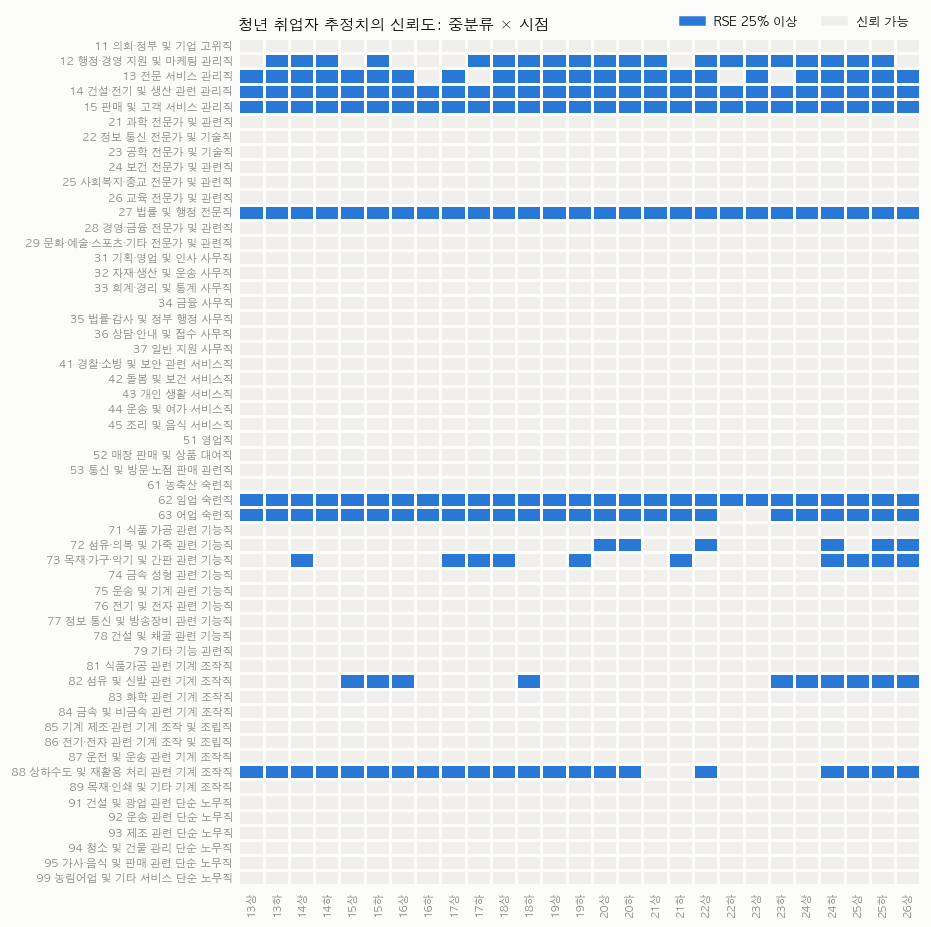

In [45]:
mid["label"] = mid.code + " " + mid.name
hm = mid.pivot(index="label", columns="period", values="y_flag").astype(int)
hm.columns = [f"{p[2:4]}{'상' if p[4:] == '01' else '하'}" for p in hm.columns]
fig, ax = plt.subplots(figsize=(8, 10))
sns.heatmap(hm, cmap=["#f0efec", BLUE], cbar=False, linewidths=0.8, linecolor=SURFACE, ax=ax)
ax.set(title="청년 취업자 추정치의 신뢰도: 중분류 × 시점", xlabel="", ylabel="")
ax.tick_params(axis="y", labelsize=7, length=0)
ax.tick_params(axis="x", labelsize=7, length=0, rotation=90)
ax.legend(handles=[Patch(color=BLUE, label="RSE 25% 이상"), Patch(color="#f0efec", label="신뢰 가능")],
          frameon=False, fontsize=8, ncol=2, loc="lower right", bbox_to_anchor=(1, 1.0))
fig.savefig(FIG / "fig3_청년셀_신뢰도.png")

share_cells = mid.y_flag.mean()
share_emp = mid.loc[mid.y_flag, "y15_29"].sum() / mid.y15_29.sum()
often = mid.groupby("code").y_flag.mean().loc[lambda s: s >= 0.5].index.tolist()
print(f"표시된 셀 {mid.y_flag.sum()}/{len(mid)} ({share_cells:.1%}), 그 셀의 청년 취업자 비중 {share_emp:.2%}")
print("시점의 절반 이상에서 표시된 중분류:", often)

### E5. 노출도: ILO 점수 → KSCO 중분류

세분류 노출도 = 연결된 ISCO 점수의 단순평균, 중분류 노출도 = 소속 세분류의 단순평균. 소분류별 취업자 가중은 자료가 없어 하지 않았다.
대신 (1) 2023년 점수, (2) 대분류를 벗어난 연결을 뺀 계산과 순위를 비교한다.

In [46]:
ilo = pd.read_excel(RAW / "ilo_wp140" / "Final_Scores_ISCO08_Gmyrek_et_al_2025.xlsx").drop_duplicates("ISCO_08")
ilo["isco"] = ilo.ISCO_08.astype(str).str.zfill(4)
lk = pd.read_excel(next((RAW / "ksco_isco").glob("*.xlsx")), sheet_name="4-1. (연계표) 세분류 연계표(KSCO-ISCO)", dtype=str)
lk = lk.rename(columns={"한국코드": "ksco", "국제코드": "isco", "대분류 벗어난 연계": "cross"})
lk["ksco"], lk["isco"], lk["cross"] = lk.ksco.str.strip(), lk.isco.str.strip().str.zfill(4), lk.cross.astype(float) > 0
m = lk.merge(ilo[["isco", "mean_score_2025", "mean_score_2023"]], on="isco", how="left")


def to_mid(df, col):
    unit = df.groupby("ksco")[col].mean()
    return unit.groupby(unit.index.str[:2]).mean()


expo = pd.DataFrame({
    "exp25": to_mid(m, "mean_score_2025"),
    "exp23": to_mid(m, "mean_score_2023"),
    "exp25_nocross": to_mid(m[~m.cross], "mean_score_2025"),
}).drop(index="A0", errors="ignore")
expo["exp_z"] = (expo.exp25 - expo.exp25.mean()) / expo.exp25.std()
expo["terc"] = pd.qcut(expo.exp25, 3, labels=ORDER).astype(str)
assert set(mid.code) == set(expo.index), "KOSIS 중분류와 노출도 코드가 다름"

rank_corr = expo[["exp25", "exp23", "exp25_nocross"]].corr(method="spearman")
display(rank_corr.round(3))

mid = mid.merge(expo, left_on="code", right_index=True)
y_base = mid[mid.year == 2022].groupby("code").y15_29.mean().rename("y_base")
terc_tbl = expo.join(y_base).groupby("terc").agg(직업수=("exp25", "size"), 노출도_평균=("exp25", "mean"),
                                                청년취업자_2022=("y_base", "sum")).loc[ORDER]
terc_tbl["청년_비중"] = terc_tbl.청년취업자_2022 / terc_tbl.청년취업자_2022.sum()
display(terc_tbl.round(3))

,exp25,exp23,exp25_nocross
exp25,1.000,0.964,0.979
exp23,0.964,1.000,0.942
exp25_nocross,0.979,0.942,1.000


,직업수,노출도_평균,청년취업자_2022,청년_비중
terc,,,,
하,19,0.166,581.5,0.146
중,18,0.262,1669.5,0.419
상,19,0.454,1734.0,0.435


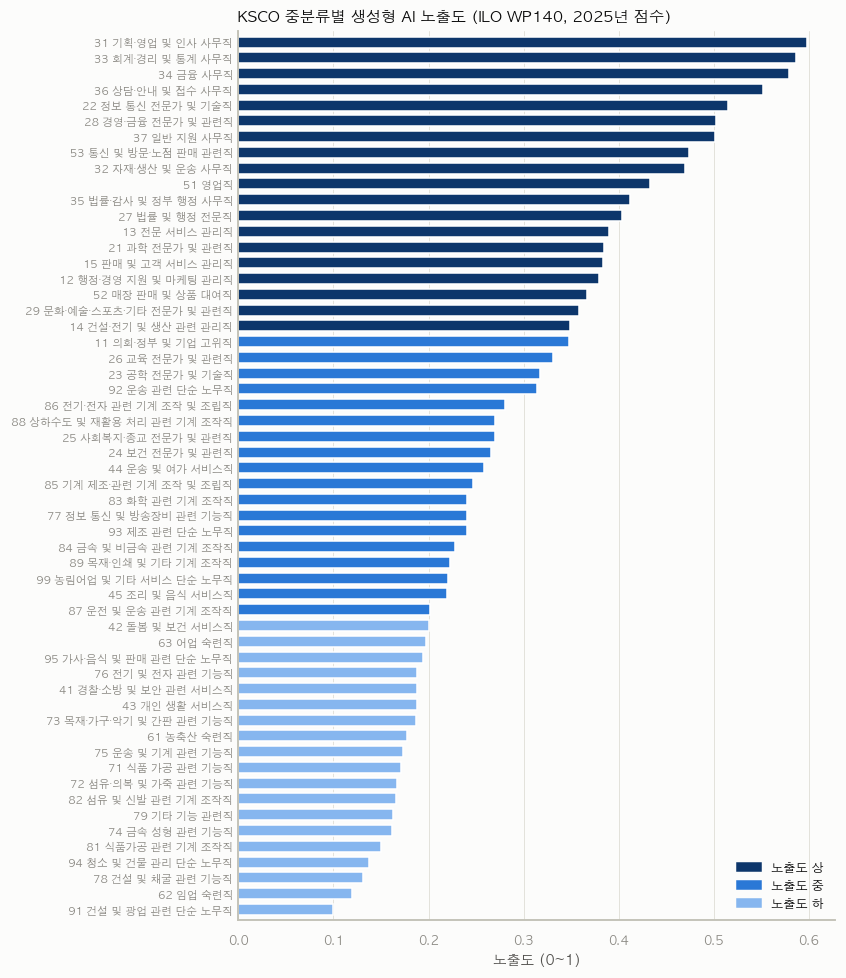

In [47]:
names = mid.drop_duplicates("code").set_index("code").name
d = expo.sort_values("exp25")
fig, ax = plt.subplots(figsize=(7, 10.5))
ax.barh([f"{c} {names[c]}" for c in d.index], d.exp25, color=d.terc.map(TERC), height=0.7)
ax.set(title="KSCO 중분류별 생성형 AI 노출도 (ILO WP140, 2025년 점수)", xlabel="노출도 (0~1)", ylabel="", ylim=(-0.7, len(d) - 0.3))
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=7, length=0)
ax.legend(handles=[Patch(color=TERC[k], label=f"노출도 {k}") for k in reversed(ORDER)], frameon=False, fontsize=8, loc="lower right")
fig.savefig(FIG / "fig4_중분류별_노출도.png")

### E6. 모델 성능 지수 (ECI)

시점별 "업그레이드 수준"은 조사 기준일(4월 15일·10월 15일)까지 출시된 모델의 ECI 최댓값으로 둔다.

,period,ref_date,eci,model,d_eci
0,202301,2023-04-15,121.87,GPT-4 (Mar 2023),NaN
1,202302,2023-10-15,121.87,GPT-4 (Mar 2023),0.00
2,202401,2024-04-15,125.87,GPT-4 Turbo (Apr 2024),4.00
3,202402,2024-10-15,135.38,o1-mini,9.51
4,202501,2025-04-15,143.91,Gemini 2.5 Pro (Mar 2025),8.53
5,202502,2025-10-15,151.17,GPT-5 Pro,7.26
6,202601,2026-04-15,160.17,GPT-5.4 Pro,9.00


처치 후 7개 시점에서 ECI 최댓값과 시점 번호의 상관: 0.978


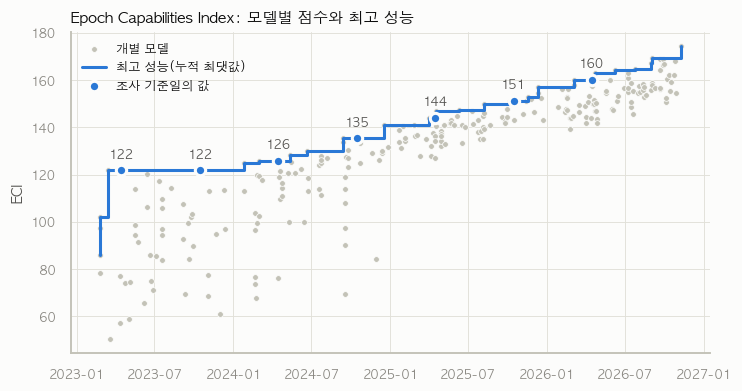

In [48]:
eci = pd.read_csv(RAW / "epoch_eci" / "eci_scores.csv", parse_dates=["date"]).sort_values("date")
eci["frontier"] = eci.eci.cummax()
ref = pd.DataFrame({"period": sorted(p for p in mid.period.unique() if p >= "202301")})
ref["ref_date"] = pd.to_datetime(ref.period.str[:4] + ref.period.str[4:].map({"01": "-04-15", "02": "-10-15"}))
top = [eci[eci.date <= d].nlargest(1, "eci").iloc[0] for d in ref.ref_date]
ref["eci"], ref["model"] = [r.eci for r in top], [r["Display name"] for r in top]
ref["d_eci"] = ref.eci.diff()
r_time = np.corrcoef(np.arange(len(ref)), ref.eci)[0, 1]
display(ref.round(2))
print(f"처치 후 {len(ref)}개 시점에서 ECI 최댓값과 시점 번호의 상관: {r_time:.3f}")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.scatter(eci.date, eci.eci, s=14, color=AXIS, edgecolor=SURFACE, linewidth=0.5, label="개별 모델", zorder=2)
ax.step(eci.date, eci.frontier, where="post", color=BLUE, lw=2, label="최고 성능(누적 최댓값)", zorder=3)
ax.scatter(ref.ref_date, ref.eci, s=46, color=BLUE, edgecolor=SURFACE, linewidth=2, label="조사 기준일의 값", zorder=4)
for r in ref.itertuples():
    ax.annotate(f"{r.eci:.0f}", (r.ref_date, r.eci), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8, color=INK2)
ax.set(title="Epoch Capabilities Index: 모델별 점수와 최고 성능", xlabel="", ylabel="ECI")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.savefig(FIG / "fig5_ECI.png")

### E7. 핵심 그림: 노출도 3분위별 취업자 추이

중분류 56개를 노출도 순으로 세 묶음으로 나누고, 묶음별 취업자 합계를 2022년 평균 = 100으로 지수화한다.

,청년 지수(2026 상),30~59세 지수(2026 상),청년 비중 %(2026 상),청년 비중 %(2022)
terc,,,,
하,84.6,88.7,6.4,7.3
중,90.7,99.9,14.4,16.3
상,82.1,108.6,13.3,17.3


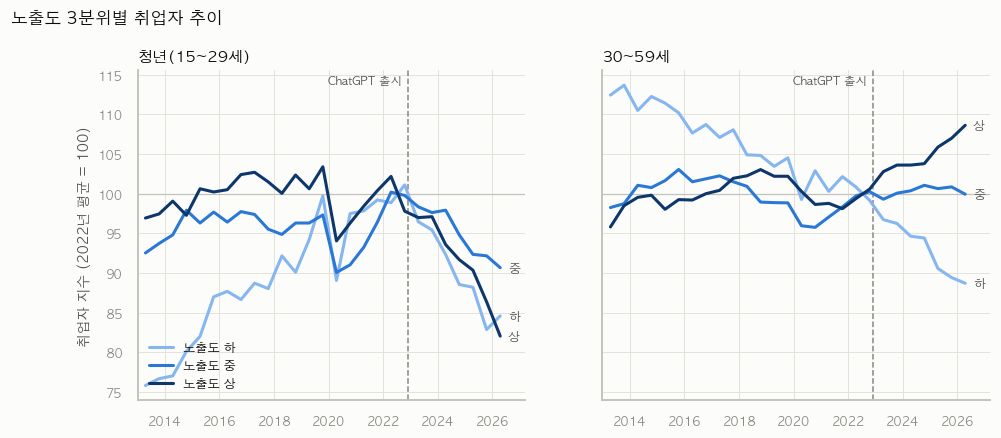

In [49]:
g = mid.groupby(["terc", "period", "time", "year"])[["y15_29", "a30_59", "total"]].sum().reset_index()
b22 = g[g.year == 2022].groupby("terc")[["y15_29", "a30_59"]].mean()
for col in ("y15_29", "a30_59"):
    g[col + "_idx"] = 100 * g[col] / g.terc.map(b22[col])
g["y_share"] = 100 * g.y15_29 / g.groupby("period").y15_29.transform("sum")   # 청년 취업자 중 이 묶음의 비중
g["y_within"] = 100 * g.y15_29 / g.total                                      # 이 묶음 취업자 중 청년 비중


def tercile_lines(axes, cols, titles):
    for ax, col, title in zip(axes, cols, titles):
        for k in ORDER:
            s = g[g.terc == k].sort_values("time")
            ax.plot(s.time, s[col], color=TERC[k], lw=2, label=f"노출도 {k}")
            end_label(ax, s.time.iloc[-1], s[col].iloc[-1], k)
        mark_chatgpt(ax)
        ax.set(title=title, xlabel="", xlim=(2013, 2027.2))


fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True)
tercile_lines(axes, ("y15_29_idx", "a30_59_idx"), ("청년(15~29세)", "30~59세"))
for ax in axes:
    ax.axhline(100, color=AXIS, lw=0.8, zorder=1)
axes[0].set_ylabel("취업자 지수 (2022년 평균 = 100)")
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.suptitle("노출도 3분위별 취업자 추이", x=0.01, y=1.02, ha="left", fontsize=11, fontweight="bold")
fig.savefig(FIG / "fig6_노출도3분위_취업자지수.png")

latest = g[g.period == "202601"].set_index("terc").loc[ORDER, ["y15_29_idx", "a30_59_idx", "y_within"]]
latest["y_within_2022"] = g[g.year == 2022].groupby("terc").y_within.mean()
display(latest.rename(columns={"y15_29_idx": "청년 지수(2026 상)", "a30_59_idx": "30~59세 지수(2026 상)", "y_within": "청년 비중 %(2026 상)", "y_within_2022": "청년 비중 %(2022)"}).round(1))

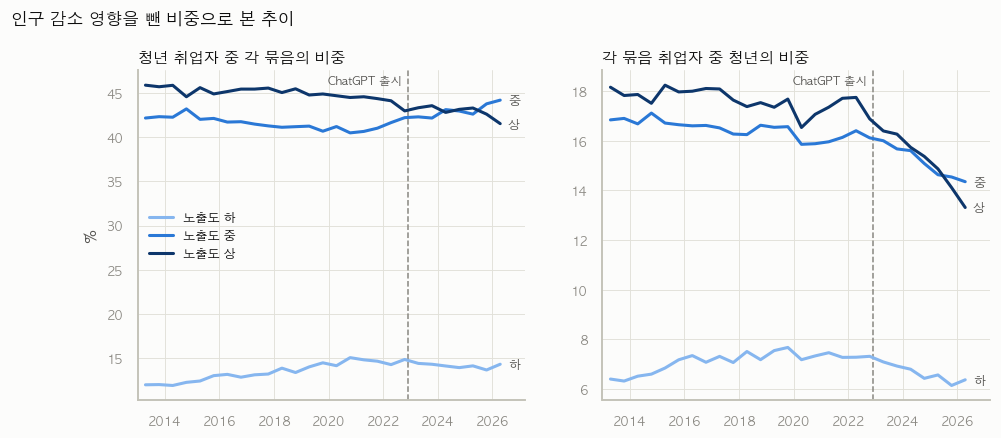

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
tercile_lines(axes, ("y_share", "y_within"), ("청년 취업자 중 각 묶음의 비중", "각 묶음 취업자 중 청년의 비중"))
axes[0].set_ylabel("%")
axes[0].legend(frameon=False, fontsize=8, loc="center left")
fig.suptitle("인구 감소 영향을 뺀 비중으로 본 추이", x=0.01, y=1.02, ha="left", fontsize=11, fontweight="bold")
fig.savefig(FIG / "fig7_노출도3분위_청년비중.png")

#### 격차 추이와 처치 전 추세

격차 = ln(노출도 상 묶음 취업자) - ln(비교 묶음 취업자). 2022년 평균을 0으로 맞췄고 단위는 로그포인트 × 100(대략 %)이다.
"청년 - 30~59세"는 같은 직업 묶음 안에서 청년이 30~59세보다 얼마나 더 줄었는지를 뜻한다(삼중차분의 기술통계).

청년  30~59세  청년 - 30~59세
상 - 하 2013           24.3   -15.2         39.4
      2016           15.2    -8.3         23.5
      2019            5.1    -1.7          6.8
      2022           -0.0     0.0          0.0
      2024            2.4     9.3         -6.8
      최근(25 하·26 상)   0.6    19.1        -18.5
상 - 중 2013            4.3    -1.4          5.7
      2016            4.4    -2.1          6.5
      2019            5.2     3.3          1.9
      2022            0.0     0.0          0.0
      2024           -3.9     2.9         -6.8
      최근(25 하·26 상)  -8.2     7.1        -15.3

처치 전 기울기(연간)  처치 후 이탈 평균  최근 2개 시점 이탈
비교    추세 기간     격차                                                
상 - 하 2013~2022 청년                  -2.91        9.95        12.62
                30~59세               1.61        7.42        12.24
                청년 - 30~59세         -4.52        2.53         0.37
      2013~2019 청년                  -2.99       10.61        13.38
                30~59세               2.25        1.67         5.70
                청년 - 30~59세         -5.24        8.94         7.68
상 - 중 2013~2022 청년                  -0.06       -7.66       -11.75
                30~59세               0.51        1.02         2.92
                청년 - 30~59세         -0.57       -8.68       -14.67
      2013~2019 청년                   0.43      -11.99       -16.70
                30~59세               0.91       -2.51        -1.12
                청년 - 30~59세         -0.48       -9.47       -15.58

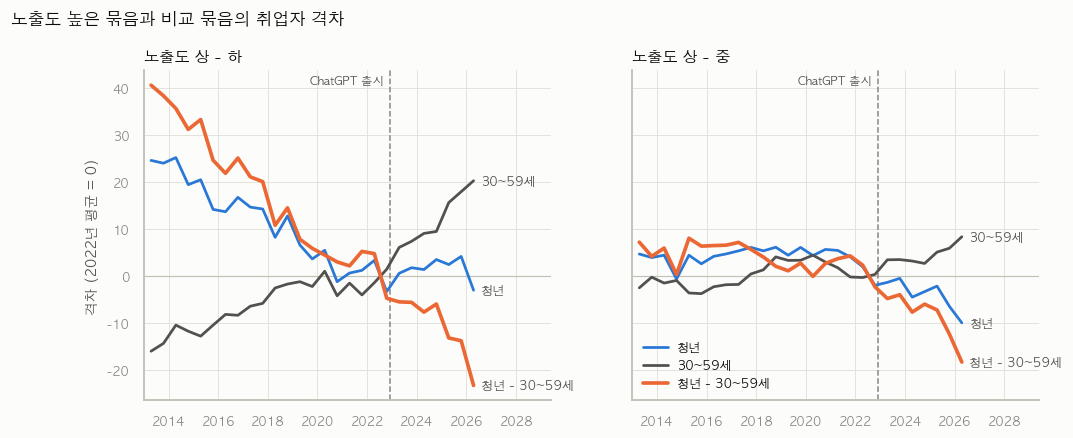

In [51]:
w = g.pivot(index="time", columns="terc", values=["y15_29", "a30_59"])


def gap_series(ref_group):
    out = pd.DataFrame({"청년": np.log(w["y15_29"]["상"] / w["y15_29"][ref_group]),
                        "30~59세": np.log(w["a30_59"]["상"] / w["a30_59"][ref_group])}) * 100
    out["청년 - 30~59세"] = out["청년"] - out["30~59세"]
    return out - out[(out.index > 2022) & (out.index < CHATGPT)].mean()


gaps = {"상 - 하": gap_series("하"), "상 - 중": gap_series("중")}
GAPC = {"청년": BLUE, "30~59세": INK2, "청년 - 30~59세": "#eb6834"}
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9), sharey=True)
for ax, (title, gp) in zip(axes, gaps.items()):
    for col in gp.columns:
        ax.plot(gp.index, gp[col], color=GAPC[col], lw=2.4 if "-" in col else 1.8, label=col)
        end_label(ax, gp.index[-1], gp[col].iloc[-1], col)
    ax.axhline(0, color=AXIS, lw=0.8, zorder=1)
    mark_chatgpt(ax)
    ax.set(title=f"노출도 {title}", xlabel="", xlim=(2013, 2029.4))
axes[0].set_ylabel("격차 (2022년 평균 = 0)")
axes[1].legend(frameon=False, fontsize=8, loc="lower left")
fig.suptitle("노출도 높은 묶음과 비교 묶음의 취업자 격차", x=0.01, y=1.02, ha="left", fontsize=11, fontweight="bold")
fig.savefig(FIG / "fig8_격차_추이.png")

levels = pd.concat({k: pd.concat([gp.groupby(gp.index.astype(int)).mean().loc[[2013, 2016, 2019, 2022, 2024]],
                                  gp[gp.index > 2025.5].mean().to_frame("최근(25 하·26 상)").T]) for k, gp in gaps.items()})
display(levels.round(1))

post_t = gaps["상 - 하"].index[gaps["상 - 하"].index > CHATGPT]
rows = []
for cname, gp in gaps.items():
    for label, pre_t in {"2013~2022": gp.index[gp.index < CHATGPT], "2013~2019": gp.index[gp.index < 2020]}.items():
        for col in gp.columns:
            slope, icpt = np.polyfit(pre_t, gp.loc[pre_t, col], 1)
            dev = gp.loc[post_t, col] - (icpt + slope * post_t)
            rows.append({"비교": cname, "추세 기간": label, "격차": col, "처치 전 기울기(연간)": slope,
                         "처치 후 이탈 평균": dev.mean(), "최근 2개 시점 이탈": dev.iloc[-2:].mean()})
trend = pd.DataFrame(rows).set_index(["비교", "추세 기간", "격차"])
display(trend.round(2))

### E8. 직업별 산점도: 노출도와 취업자 변화

계절성을 맞추기 위해 상·하반기 평균끼리 비교한다. 세 구간 모두 길이는 3.5년이다. 기준 취업자가 1천명 미만인 직업은 로그 변화를 계산할 수 없어 제외한다.

노출도 1표준편차당 취업자 변화 (로그포인트 × 100)


직업 수  가중 기울기  단순 기울기
구간                            대상                               
처치 후 (2022 → 2025 하·2026 상)   청년             52   -1.99    0.01
                              30~59세         56    8.02    8.78
                              청년 - 30~59세    52   -7.56   -9.45
플라시보 1 (2015 → 2018 하·2019 상) 청년             53   -2.50   -0.40
                              30~59세         56    5.11    5.15
                              청년 - 30~59세    53   -6.51   -5.89
플라시보 2 (2018 하·2019 상 → 2022) 청년             52   -2.76   -2.59
                              30~59세         56    1.48    4.10
                              청년 - 30~59세    52   -3.54   -5.14

청년: 직업 하나씩 빼고 다시 계산한 가중 기울기 -3.13 ~ 0.31 (가장 크게 바꾸는 직업: 31 기획·영업 및 인사 사무직, 45 조리 및 음식 서비스직)
청년 - 30~59세: 직업 하나씩 빼고 다시 계산한 가중 기울기 -8.71 ~ -5.86 (가장 크게 바꾸는 직업: 31 기획·영업 및 인사 사무직, 45 조리 및 음식 서비스직)


,직업,노출도,"청년 취업자(2022, 천명)",청년 변화,30~59세 변화
code,,,,,
45,조리 및 음식 서비스직,0.22,419.5,5.68,3.22
52,매장 판매 및 상품 대여직,0.37,331.0,-23.57,-14.05
24,보건 전문가 및 관련직,0.27,281.0,-7.77,18.94
37,일반 지원 사무직,0.50,232.0,-21.83,2.94
29,문화·예술·스포츠·기타 전문가 및 관련직,0.36,227.5,-10.41,25.54
26,교육 전문가 및 관련직,0.33,217.0,-17.04,0.89
33,회계·경리 및 통계 사무직,0.59,148.5,-34.19,6.44
23,공학 전문가 및 기술직,0.32,136.0,7.10,16.16


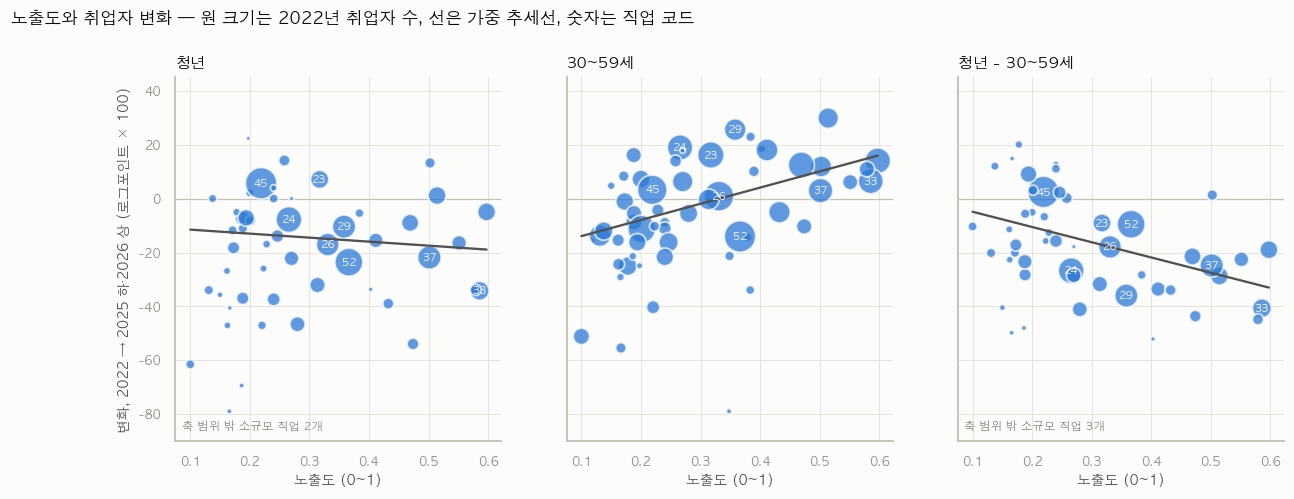

In [52]:
WINDOWS = {
    "처치 후 (2022 → 2025 하·2026 상)": (["202201", "202202"], ["202502", "202601"]),
    "플라시보 1 (2015 → 2018 하·2019 상)": (["201501", "201502"], ["201802", "201901"]),
    "플라시보 2 (2018 하·2019 상 → 2022)": (["201802", "201901"], ["202201", "202202"]),
}


def window_change(col, pre, post):
    a = mid[mid.period.isin(pre)].groupby("code")[col].mean()
    b = mid[mid.period.isin(post)].groupby("code")[col].mean()
    with np.errstate(divide="ignore"):
        out = pd.DataFrame({"base": a, "dln": 100 * np.log(b / a)}).join(expo[["exp25", "exp_z"]])
    return out[(out.base >= 1) & np.isfinite(out.dln)]


def changes(pre, post):
    """청년, 30~59세, 그리고 둘의 차이(같은 직업 안에서 청년이 더 줄어든 정도). 가중치는 청년 기준 취업자."""
    y, a = window_change("y15_29", pre, post), window_change("a30_59", pre, post)
    diff = y.join(a.dln.rename("dln_a"), how="inner")
    diff["dln"] = diff.dln - diff.dln_a
    return {"청년": y, "30~59세": a, "청년 - 30~59세": diff}


def wslope(df, x="exp_z"):
    return np.polyfit(df[x], df.dln, 1, w=np.sqrt(df.base))[0]


rows = []
for wname, (pre, post) in WINDOWS.items():
    for lab, dfw in changes(pre, post).items():
        rows.append({"구간": wname, "대상": lab, "직업 수": len(dfw), "가중 기울기": wslope(dfw), "단순 기울기": np.polyfit(dfw.exp_z, dfw.dln, 1)[0]})
slopes = pd.DataFrame(rows).set_index(["구간", "대상"])
print("노출도 1표준편차당 취업자 변화 (로그포인트 × 100)")
display(slopes.round(2))

MAIN = "처치 후 (2022 → 2025 하·2026 상)"
sc = changes(*WINDOWS[MAIN])
loo = {lab: pd.Series({c: wslope(sc[lab].drop(index=c)) for c in sc[lab].index}) for lab in ("청년", "청년 - 30~59세")}
for lab, s_ in loo.items():
    print(f"{lab}: 직업 하나씩 빼고 다시 계산한 가중 기울기 {s_.min():.2f} ~ {s_.max():.2f} "
          f"(가장 크게 바꾸는 직업: {s_.idxmin()} {names[s_.idxmin()]}, {s_.idxmax()} {names[s_.idxmax()]})")

YLIM = (-90, 45)
to_label = sc["청년"].base.nlargest(8).index
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), sharey=True)
for ax, (lab, dfw) in zip(axes, sc.items()):
    ax.scatter(dfw.exp25, dfw.dln, s=6 + dfw.base / dfw.base.max() * 420, color=BLUE, alpha=0.75, edgecolor=SURFACE, linewidth=1.2, zorder=3)
    s1, s0 = np.polyfit(dfw.exp25, dfw.dln, 1, w=np.sqrt(dfw.base))
    xs = np.array([dfw.exp25.min(), dfw.exp25.max()])
    ax.plot(xs, s0 + s1 * xs, color=INK2, lw=1.5, zorder=4)
    ax.axhline(0, color=AXIS, lw=0.8, zorder=1)
    for c in to_label:
        if c in dfw.index:
            ax.annotate(c, (dfw.exp25[c], dfw.dln[c]), ha="center", va="center", fontsize=7, color="white", fontweight="bold", zorder=5)
    n_out = int(((dfw.dln < YLIM[0]) | (dfw.dln > YLIM[1])).sum())
    if n_out:
        ax.text(0.02, 0.03, f"축 범위 밖 소규모 직업 {n_out}개", transform=ax.transAxes, fontsize=7.5, color=MUTED)
    ax.set(title=lab, xlabel="노출도 (0~1)", ylim=YLIM)
axes[0].set_ylabel("변화, 2022 → 2025 하·2026 상 (로그포인트 × 100)")
fig.suptitle("노출도와 취업자 변화 — 원 크기는 2022년 취업자 수, 선은 가중 추세선, 숫자는 직업 코드", x=0.01, y=1.02, ha="left", fontsize=11, fontweight="bold")
fig.savefig(FIG / "fig9_노출도_변화_산점도.png")

lookup = sc["청년"].loc[to_label, ["exp25", "base", "dln"]].join(sc["30~59세"].dln.rename("dln_30_59"))
lookup.insert(0, "직업", names[lookup.index])
display(lookup.rename(columns={"exp25": "노출도", "base": "청년 취업자(2022, 천명)", "dln": "청년 변화", "dln_30_59": "30~59세 변화"}).round(2))

### E9. 진입 판단

In [53]:
s = slopes["가중 기울기"]
fmt3 = lambda lab: " / ".join(f"{s[(k, lab)]:.2f}" for k in WINDOWS)   # 처치 후 / 플라시보 1 / 플라시보 2
pre_slope = lambda lab: trend.loc[("상 - 하", "2013~2022", lab), "처치 전 기울기(연간)"]
same_sign = lambda x: bool(np.sign(x.min()) == np.sign(x.max()))
checks = pd.DataFrame([
    ("E1 합계 일치", f"최대 차이 {max(d_mid, d_maj, d_age):.0f}천명", max(d_mid, d_maj, d_age) <= 3),
    ("E4 신뢰 가능한 셀의 청년 취업자 비중 ≥ 90%", f"{1 - share_emp:.1%}", 1 - share_emp >= 0.9),
    ("E5 노출도가 붙은 중분류", f"{expo.exp25.notna().sum()}/{mid.code.nunique()}", bool(expo.exp25.notna().all())),
    ("E5 계산 방식 간 순위상관 ≥ 0.9", f"최소 {rank_corr.values.min():.3f}", bool(rank_corr.values.min() >= 0.9)),
    ("E7 처치 전 기울기(연간, 상-하): 청년", f"{pre_slope('청년'):.2f}", "판단 필요"),
    ("E7 처치 전 기울기(연간, 상-하): 청년 - 30~59세", f"{pre_slope('청년 - 30~59세'):.2f}", "판단 필요"),
    ("E8 가중 기울기, 청년 (처치 후 / 플라시보 1 / 2)", fmt3("청년"), "판단 필요"),
    ("E8 가중 기울기, 청년 - 30~59세 (처치 후 / 플라시보 1 / 2)", fmt3("청년 - 30~59세"), "판단 필요"),
    ("E8 직업 하나를 빼도 부호 유지: 청년", f"{loo['청년'].min():.2f} ~ {loo['청년'].max():.2f}", same_sign(loo["청년"])),
    ("E8 직업 하나를 빼도 부호 유지: 청년 - 30~59세", f"{loo['청년 - 30~59세'].min():.2f} ~ {loo['청년 - 30~59세'].max():.2f}", same_sign(loo["청년 - 30~59세"])),
], columns=["점검", "값", "통과"])
display(checks)

cols = ["code", "name", "major", "period", "year", "half", "time", "post", "total", "y15_29", "a30_39", "a40_49", "a50_59", "a60p",
        "a30_59", "y_flag", "exp25", "exp23", "exp25_nocross", "exp_z", "terc"]
mid[cols].to_csv(OUT / "panel_mid.csv", index=False, encoding="utf-8-sig")
ref.to_csv(OUT / "eci_ref.csv", index=False, encoding="utf-8-sig")
print("저장:", OUT / "panel_mid.csv", mid[cols].shape, "|", OUT / "eci_ref.csv", ref.shape)

,점검,값,통과
0,E1 합계 일치,최대 차이 3천명,True
1,E4 신뢰 가능한 셀의 청년 취업자 비중 ≥ 90%,99.6%,True
2,E5 노출도가 붙은 중분류,56/56,True
3,E5 계산 방식 간 순위상관 ≥ 0.9,최소 0.942,True
4,"E7 처치 전 기울기(연간, 상-하): 청년",-2.91,판단 필요
5,"E7 처치 전 기울기(연간, 상-하): 청년 - 30~59세",-4.52,판단 필요
6,"E8 가중 기울기, 청년 (처치 후 / 플라시보 1 / 2)",-1.99 / -2.50 / -2.76,판단 필요
7,"E8 가중 기울기, 청년 - 30~59세 (처치 후 / 플라시보 1 / 2)",-7.56 / -6.51 / -3.54,판단 필요
8,E8 직업 하나를 빼도 부호 유지: 청년,-3.13 ~ 0.31,False
9,E8 직업 하나를 빼도 부호 유지: 청년 - 30~59세,-8.71 ~ -5.86,True


저장: /Users/muju/DA_Final_Project/data/processed/panel_mid.csv (1512, 21) | /Users/muju/DA_Final_Project/data/processed/eci_ref.csv (7, 5)


### 요약과 판단 (2026-11-11 실행 기준)

**데이터 품질은 모두 통과했다.** 합계 차이 최대 3천명, 신뢰 가능한 셀의 청년 취업자 비중 99.6%, 노출도 매칭 56/56, 계산 방식 간 순위상관 최소 0.942.

**보이는 것**

1. 2022년 이후 청년 취업자는 노출도 세 묶음 모두에서 줄었다(2022년 평균 = 100 → 2026 상: 상 82.1, 중 90.7, 하 84.6).
2. 노출도 상 묶음에서는 30~59세가 늘었는데(108.6) 청년만 줄었다. 이 묶음의 청년 비중은 17.3% → 13.3%로, 중(16.3 → 14.4)·하(7.3 → 6.4)보다 크게 떨어졌다.

**그러나 "2022년 이후에 새로 생긴 변화"라는 근거는 약하다**

3. 청년만 보면 노출도 상-하 격차는 2013~2022년에 이미 연 2.9씩 줄었고, 2022년 이후에는 거의 변하지 않았다(+0.6).
4. 청년 - 30~59세 격차(상-하)는 2022년 이전부터 연 4.5씩 줄어 왔고 이후에도 같은 속도다(추세 연장선과의 차이 0.4~2.5).
5. 직업 단위 기울기도 같은 결론이다. 노출도 1표준편차당 청년 - 30~59세 변화는 처치 후 -7.6, 처치 전 두 구간 -6.5와 -3.5였다. 청년만의 기울기(-2.0)는 처치 전(-2.5, -2.8)보다 작고, 직업 하나(45 조리 및 음식 서비스직)를 빼면 부호가 바뀐다.
6. 상-중 비교에서만 2022년 이후 꺾임이 보인다. 청년 - 30~59세 격차가 처치 전 연 -0.6에서 이후 3.5년간 -15.3이 됐다.

**판단**

- 청년만의 단순 이중차분(M2)은 평행추세 가정이 성립하지 않는다. 설계 3-5의 기준대로 인과 해석을 하지 않고 "기존 추세의 연장"으로 보고한다.
- 회귀 단계의 주 분석은 직업 안의 청년 대 30~59세 비교(M3)로 옮기고, 수준 변화가 아니라 2022년 이후 추세가 꺾였는지를 검정한다.
- 하 묶음은 청년 취업자의 14.6%뿐이고 2013~2020년에 청년이 크게 늘어난 뒤 줄어드는 등 움직임이 다르다. 상-하와 상-중의 결과가 갈리는 이유를 직업별로 확인해야 한다.

## 2부. 전처리 — 분석용 패널 만들기

- 입력: `data/processed/panel_mid.csv` (01_panel.ipynb가 만든 직업 중분류 × 반기 패널), `data/processed/eci_ref.csv`
- 출력: `data/processed/panel_analysis.csv`, `data/processed/panel_analysis_codebook.csv`
- 경로는 `src/config.py`를 따른다.

제외 규칙은 설계 문서 8-1절에서 결과를 보기 전에 정한 것이다. 바꾸려면 설계 문서에 이유를 남긴다.

In [54]:
import sys

sys.path.append("..")  # 노트북 폴더 기준으로 src를 찾는다 (README 6절)
from src import config

import numpy as np
import pandas as pd

try:
    display
except NameError:  # 스크립트로 실행할 때
    def display(x):
        print(x.to_string() if hasattr(x, "to_string") else x)

OUT = config.DATA_PROCESSED
p = pd.read_csv(OUT / "panel_mid.csv", dtype={"code": str, "period": str})
eci = pd.read_csv(OUT / "eci_ref.csv", dtype={"period": str})

EXCL_MAIN = ["11", "12", "13", "14", "15", "62"]   # 청년 0명인 칸이 있는 직업
EXCL_ROBUST = EXCL_MAIN + ["27", "63", "88"]       # + 청년 오차 표시가 시점 절반 이상인 직업
COVID = ["202001", "202002", "202101", "202102"]   # 2020 상 ~ 2021 하

### 1. 시점 변수

`k_post`: 2023년 상반기 = 1 … 2026년 상반기 = 7, 그 전은 0. H1 식에서 "2023년 이후 기울기 변화"를 재는 변수다.

In [55]:
order = {per: i for i, per in enumerate(sorted(p.period.unique()))}
p["k_post"] = (p.period.map(order) - order["202202"]).clip(lower=0)

### 2. AI 성능(ECI)

2023년 이전은 자료가 없어 빈칸이다. `eci_lag1`은 한 반기 전 값으로, 영향이 늦게 나타나는 경우를 볼 때(H3) 쓴다.

In [56]:
eci = eci.sort_values("period")
eci["eci_lag1"] = eci.eci.shift(1)
p = p.merge(eci[["period", "eci", "eci_lag1", "d_eci"]], on="period", how="left")

### 3. 결과 변수와 가중치

- `lr_y` = ln(청년) − ln(30~59세): 주 결과변수. 청년이 0명인 칸은 계산할 수 없어 빈칸이다.
- `y_share` = 청년 ÷ 전체(%): 보조 결과변수.
- `w`: 2022년 상·하반기 청년 취업자 평균. 직업마다 하나로 고정한다(결과가 가중치에 섞이지 않도록).

In [57]:
with np.errstate(divide="ignore"):
    p["lr_y"] = np.log(p.y15_29) - np.log(p.a30_59)
p.loc[p.y15_29 == 0, "lr_y"] = np.nan
p["y_share"] = 100 * p.y15_29 / p.total
p = p.merge(p[p.year == 2022].groupby("code").y15_29.mean().rename("w"), on="code", how="left")

### 4. 표본 표시

In [58]:
p["in_main"] = ~p.code.isin(EXCL_MAIN)
p["in_robust47"] = ~p.code.isin(EXCL_ROBUST)
p["covid"] = p.period.isin(COVID)

### 5. 검사 — 하나라도 어긋나면 여기서 멈춘다

In [59]:
main = p[p.in_main]
checks = {
    "(직업, 시점) 조합 중복 없음": not p.duplicated(["code", "period"]).any(),
    "전체 1,512행 (56개 직업 × 27개 시점)": len(p) == 1512 and p.code.nunique() == 56,
    "주 분석 1,350행 (50개 직업)": len(main) == 1350 and main.code.nunique() == 50,
    "검증용 표본 47개 직업": p[p.in_robust47].code.nunique() == 47,
    "주 분석에 lr_y 빈칸·무한대 없음": bool(np.isfinite(main.lr_y).all()),
    "lr_y 빈칸은 청년 0명인 칸만 (88칸)": p.lr_y.isna().sum() == (p.y15_29 == 0).sum() == 88,
    "주 분석 가중치가 모두 양수": bool((main.w > 0).all()),
    "노출도 0~1, 청년 비중 0~100%": bool(p.exp25.between(0, 1).all() and p.y_share.between(0, 100).all()),
    "k_post 0~7이고 post와 일치": bool(p.k_post.between(0, 7).all() and ((p.k_post > 0) == p.post).all()),
    "ECI는 2023년 이후에만 있음": bool(p.loc[p.post, "eci"].notna().all() and p.loc[~p.post, "eci"].isna().all()),
}
for name, ok in checks.items():
    print(("통과  " if ok else "실패  ") + name)
assert all(checks.values()), "검사 실패: 위 목록을 확인"

통과  (직업, 시점) 조합 중복 없음
통과  전체 1,512행 (56개 직업 × 27개 시점)
통과  주 분석 1,350행 (50개 직업)
통과  검증용 표본 47개 직업
통과  주 분석에 lr_y 빈칸·무한대 없음
통과  lr_y 빈칸은 청년 0명인 칸만 (88칸)
통과  주 분석 가중치가 모두 양수
통과  노출도 0~1, 청년 비중 0~100%
통과  k_post 0~7이고 post와 일치
통과  ECI는 2023년 이후에만 있음


### 6. 저장

In [60]:
COLS = ["code", "name", "major", "period", "year", "half", "time", "post", "k_post",
        "total", "y15_29", "a30_39", "a40_49", "a50_59", "a60p", "a30_59", "y_flag",
        "exp25", "exp23", "exp25_nocross", "exp_z", "terc",
        "eci", "eci_lag1", "d_eci", "lr_y", "y_share", "w", "in_main", "in_robust47", "covid"]
p = p.sort_values(["code", "period"])[COLS]
p.to_csv(OUT / "panel_analysis.csv", index=False, encoding="utf-8-sig")

codebook = pd.DataFrame([
    ("code", "직업 중분류 코드", "글자 '11'~'99'", "KOSIS DT_1ES3B28J", "글자로 읽기 (dtype={'code': str})"),
    ("name", "직업 이름", "", "KOSIS DT_1ES3B28J", ""),
    ("major", "직업 대분류 번호", "1~9", "code의 첫 자리", ""),
    ("period", "시점", "'201301' = 2013 상반기, '201302' = 하반기", "KOSIS DT_1ES3B28J", "글자로 읽기 (dtype={'period': str})"),
    ("year", "연도", "", "period", ""),
    ("half", "반기", "1 = 상반기(4월 조사), 2 = 하반기(10월 조사)", "period", ""),
    ("time", "소수로 쓴 연도", "2013.29 = 2013년 4월", "연도 + 조사월/12", "그래프 x축용"),
    ("post", "AI 이후 여부", "True/False", "2023 상반기부터 True", "ChatGPT 출시(2022-11-30)가 2022 하반기 조사(10월)보다 늦음"),
    ("k_post", "AI 이후 몇 번째 반기", "0~7", "2023 상 = 1 … 2026 상 = 7, 그 전 0", "H1 기울기 변화 변수"),
    ("total", "전체 취업자", "천명", "KOSIS DT_1ES3B28J", ""),
    ("y15_29", "청년(15~29세) 취업자", "천명", "KOSIS DT_1ES3B28J", "'-'(해당자 없음)는 0으로 바꿈"),
    ("a30_39", "30대 취업자", "천명", "KOSIS DT_1ES3B28J", ""),
    ("a40_49", "40대 취업자", "천명", "KOSIS DT_1ES3B28J", ""),
    ("a50_59", "50대 취업자", "천명", "KOSIS DT_1ES3B28J", ""),
    ("a60p", "60세 이상 취업자", "천명", "KOSIS DT_1ES3B28J", ""),
    ("a30_59", "30~59세 취업자", "천명", "a30_39 + a40_49 + a50_59", "비교군"),
    ("y_flag", "청년 추정치 오차가 큼", "True/False", "KOSIS의 '*' 표시 (상대표준오차 25% 이상)", "전체 칸의 14.7%"),
    ("exp25", "AI 노출도 (주 분석)", "0~1", "ILO WP140 2025 점수 → 연계표로 한국 세분류 평균 → 중분류 평균", "단순평균 (취업자 가중 아님)"),
    ("exp23", "AI 노출도 (2023 점수)", "0~1", "exp25와 같은 방법, ILO 2023 점수", "검증용"),
    ("exp25_nocross", "AI 노출도 (대분류 벗어난 연결 제외)", "0~1", "exp25와 같은 방법", "검증용. 직업 88은 빈칸"),
    ("exp_z", "AI 노출도 표준화 값", "평균 0, 표준편차 1", "(exp25 − 평균) ÷ 표준편차, 56개 직업 기준", "회귀 결과를 '1표준편차당'으로 읽을 때"),
    ("terc", "노출도 3분위", "하 / 중 / 상", "exp25 순위로 3등분 (19 / 18 / 19개 직업)", "그림용"),
    ("eci", "그 시점의 최고 AI 성능", "ECI 점수", "Epoch eci_scores.csv, 조사 기준일까지 나온 모델 중 최고점", "2023년 이전 빈칸. 2026-11-11 파일 기준"),
    ("eci_lag1", "한 반기 전 ECI", "ECI 점수", "eci를 한 반기 늦춤", "2023 상반기 포함 빈칸"),
    ("d_eci", "직전 반기 대비 ECI 상승폭", "ECI 점수", "eci − eci_lag1", "H3"),
    ("lr_y", "주 결과변수: ln(청년 ÷ 30~59세)", "로그 (0.05 감소 ≈ 상대 비율 5% 감소)", "ln(y15_29) − ln(a30_59)", "청년 0명인 칸은 빈칸 (88칸, 모두 주 분석 제외 직업)"),
    ("y_share", "보조 결과변수: 청년 비중", "%", "100 × y15_29 ÷ total", "60세 이상 증가의 영향이 섞임"),
    ("w", "가중치", "천명", "2022년 상·하반기 청년 취업자 평균, 직업마다 고정", ""),
    ("in_main", "주 분석 표본", "True/False", "직업 11·12·13·14·15·62 제외", "50개 직업 × 27개 시점 = 1,350행"),
    ("in_robust47", "검증용 표본", "True/False", "위 6개 + 27·63·88 제외", "47개 직업"),
    ("covid", "코로나 시기", "True/False", "2020 상반기 ~ 2021 하반기", "제외 분석용"),
], columns=["열", "뜻", "단위·값", "출처·계산", "비고"])
assert list(codebook["열"]) == COLS, "변수 설명표와 실제 열이 다름"
codebook.to_csv(OUT / "panel_analysis_codebook.csv", index=False, encoding="utf-8-sig")
print("저장:", OUT / "panel_analysis.csv", p.shape, "|", OUT / "panel_analysis_codebook.csv", codebook.shape)
display(p[p.code.isin(["33", "45"]) & p.period.isin(["202202", "202601"])])

저장: /Users/muju/DA_Final_Project/data/processed/panel_analysis.csv (1512, 31) | /Users/muju/DA_Final_Project/data/processed/panel_analysis_codebook.csv (31, 5)


,code,name,major,period,year,half,time,post,k_post,total,...,terc,eci,eci_lag1,d_eci,lr_y,y_share,w,in_main,in_robust47,covid
451,33,회계·경리 및 통계 사무직,3,202202,2022,2,2022.791667,False,0,856.0,...,상,NaN,NaN,NaN,-1.537464,16.822430,148.5,True,True,False
458,33,회계·경리 및 통계 사무직,3,202601,2026,1,2026.291667,True,7,891.0,...,상,160.17,151.17,9.0,-1.920874,11.672278,148.5,True,True,False
694,45,조리 및 음식 서비스직,4,202202,2022,2,2022.791667,False,0,1686.0,...,중,NaN,NaN,NaN,-0.760637,26.334520,419.5,True,True,False
701,45,조리 및 음식 서비스직,4,202601,2026,1,2026.291667,True,7,1780.0,...,중,160.17,151.17,9.0,-0.765152,24.831461,419.5,True,True,False


### 쓰는 법

```python
df = pd.read_csv(config.DATA_PROCESSED / "panel_analysis.csv", dtype={"code": str, "period": str})
main = df[df.in_main]          # 주 분석 (50개 직업)
robust = df[df.in_robust47]    # 검증용 (47개 직업)
no_covid = main[~main.covid]   # 코로나 시기 제외
```